In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
df = pd.read_csv("../Task_1_Data_Cleaning/output/Netflix_Cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [27]:
rating_counts = df["rating"].value_counts()

print("Netflix Rating Categories:")
display(rating_counts)

Netflix Rating Categories:


rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

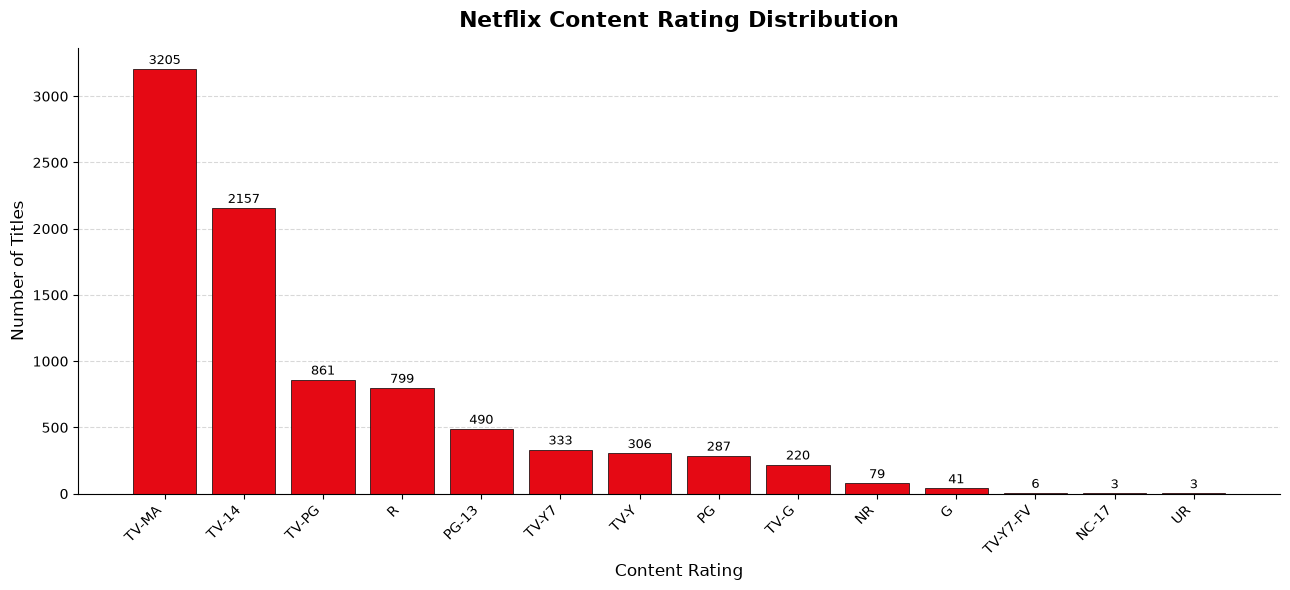

In [37]:
# Netflix Content Rating Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate rating counts
rating_counts = df["rating"].value_counts()

# Create figure
plt.figure(figsize=(13, 6))

# Netflix Red bar chart
bars = plt.bar(
    rating_counts.index,
    rating_counts.values,
    color="#E50914",
    edgecolor="black",
    linewidth=0.5
)

# Add values above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 15,
        f"{int(height)}",
        ha="center",
        va="bottom",
        fontsize=9
    )

# Title and labels
plt.title(
    "Netflix Content Rating Distribution",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Content Rating", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

# Styling
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", color="grey", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [29]:
genre_df = df[["title", "listed_in"]].copy()

genre_df["listed_in"] = genre_df["listed_in"].str.split(",")

genre_df = genre_df.explode("listed_in")

genre_df["listed_in"] = genre_df["listed_in"].str.strip()

genre_counts = genre_df["listed_in"].value_counts()

print("Total Unique Genres:", genre_df["listed_in"].nunique())

print("\nTop 10 Most Common Genres:")
display(genre_counts.head(10))

Total Unique Genres: 42

Top 10 Most Common Genres:


listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

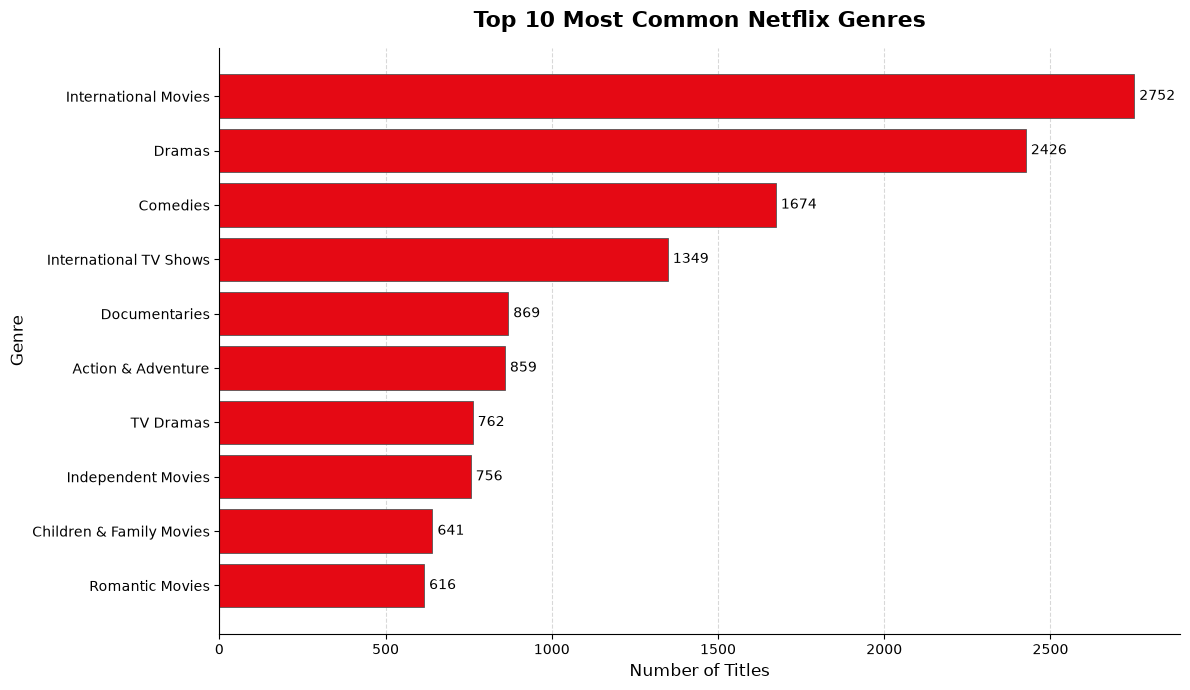

In [38]:
# Top 10 Most Common Netflix Genres

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate top 10 genres
genre_counts = (
    df["listed_in"]
    .str.split(", ")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    genre_counts.index,
    genre_counts.values,
    color="#E50914",
    edgecolor="#555555",
    linewidth=0.6
)

# Add values at the end of each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=10
    )

plt.title(
    "Top 10 Most Common Netflix Genres",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Genre", fontsize=12)

plt.grid(axis="x", linestyle="--", color="grey", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()
plt.tight_layout()
plt.show()

In [31]:
rating_type_counts = (
    df.groupby(["rating", "type"])
    .size()
    .unstack(fill_value=0)
)

print("Rating Comparison: Movies vs TV Shows")
display(rating_type_counts)

Rating Comparison: Movies vs TV Shows


type,Movie,TV Show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143


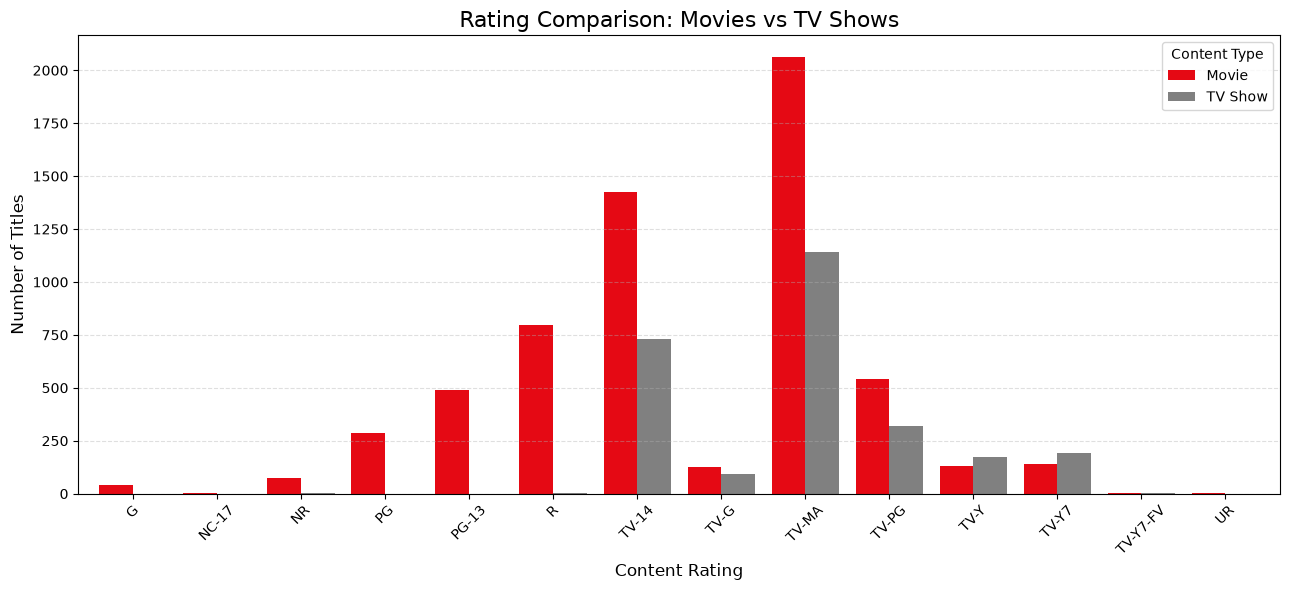

In [32]:
rating_type_counts.plot(
    kind="bar",
    figsize=(13, 6),
    color=["#E50914", "grey"],
    width=0.8
)

plt.title("Rating Comparison: Movies vs TV Shows", fontsize=16)
plt.xlabel("Content Rating", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)

plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [33]:
%pip install plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\ayaan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [34]:
import plotly.express as px

In [35]:
genre_type_df = df[["type", "listed_in"]].copy()

genre_type_df["listed_in"] = genre_type_df["listed_in"].str.split(",")

genre_type_df = genre_type_df.explode("listed_in")

genre_type_df["listed_in"] = genre_type_df["listed_in"].str.strip()

genre_type_counts = (
    genre_type_df.groupby(["listed_in", "type"])
    .size()
    .reset_index(name="count")
)

fig = px.bar(
    genre_type_counts,
    x="listed_in",
    y="count",
    color="type",
    barmode="group",
    title="Interactive Netflix Genre Analysis",
    labels={
        "listed_in": "Genre",
        "count": "Number of Titles",
        "type": "Content Type"
    },
    color_discrete_map={
        "Movie": "#E50914",
        "TV Show": "grey"
    }
)

fig.update_layout(
    xaxis_tickangle=-45,
    height=650,
    template="plotly_white"
)

fig.show()

In [36]:
%pip install nbformat

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\ayaan\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


### Key Audience Insights

1. **Mature Content Preference:** TV-MA is the most common rating, followed by TV-14, showing strong representation of mature-audience content.

2. **Popular Genres:** International Movies, Dramas and Comedies are the three most common genres in the dataset.

3. **Movie Distribution:** Movies have higher counts in most rating categories, particularly TV-MA and TV-14.

4. **Family Content:** TV Shows have higher counts than Movies in TV-Y and TV-Y7 categories.

5. **Genre Diversity:** Netflix content is distributed across 42 unique genres, indicating a diverse content library.

6. **Business Observation:** Netflix can use rating and genre patterns to understand its content distribution and plan content categories for different audience groups.

### Conclusion

The analysis shows that TV-MA and TV-14 are the most common content ratings, while International Movies, Dramas and Comedies are the leading genres. Movies dominate most rating categories, whereas TV Shows have greater representation in some children's rating categories. These findings provide useful insights into Netflix's content distribution and audience categories.